# 4. Model evaluation

Fits the two model variants with the pipeline's code on the chronological split, and checks what matters for this problem: does it beat simple baselines, are the probabilities calibrated, does the range hold 8 in 10 flights, where is it wrong, and what does it rely on. It ends with what happens when the split is random instead of chronological.

Default hyperparameters keep this to a couple of minutes; `make evaluate` tunes them and writes the full report (`docs/results/evaluation.md`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import nbutils
from nbutils import BLUE, GREEN, GREY, ORANGE, RED

nbutils.setup()

In [2]:
from aeroscrape.models.baselines import GroupMedianRegressor
from aeroscrape.models.experiment import fit_variant, make_splits, tune_models
from aeroscrape.features.preprocess import prepare_input

config = nbutils.project_config()
flights, _ = nbutils.load_flights()
splits = make_splits(flights, config)
display(splits.describe(config["evaluation"]["time_column"]))
nbutils.show_inline()
params = tune_models(splits, config, enabled=False)
fits = {variant: fit_variant(variant, params.by_variant[variant], splits, config) for variant in ["booking", "pre_departure"]}

Ignoring 3 implausible delays outside [-60, 720] min


,rows,start,end
train,2398,2025-05-22 00:20:00,2025-06-04 23:30:00
val,489,2025-06-06 04:30:00,2025-06-09 23:30:00
test,687,2025-06-10 04:40:00,2025-06-12 23:50:00


## Against the baselines

In [3]:
test = splits.test
y = test["delay_minutes"].to_numpy()
late = (y > 15).astype(int)
baseline = GroupMedianRegressor(["airline", "scheduled_time_of_day"]).fit(splits.train_val, splits.train_val["delay_minutes"]).predict(test)
airline_rate = test["airline"].map(splits.train_val.assign(l=splits.train_val["delay_minutes"] > 15).groupby("airline")["l"].mean()).fillna((splits.train_val["delay_minutes"] > 15).mean()).to_numpy()

rows = [{"model": "baseline: airline × time-of-day median, airline delay rate", "MAE": np.mean(np.abs(y - baseline)), "Brier": np.mean((airline_rate - late) ** 2), "coverage": np.nan}]
outputs = {}
for variant, fit in fits.items():
    X = prepare_input(test, fit.bundle.features)
    out = fit.bundle.predict(X)
    outputs[variant] = out
    rows.append({
        "model": f"LightGBM, {variant.replace('_', ' ')}",
        "MAE": np.mean(np.abs(y - out["p50"])),
        "Brier": np.mean((out["p_delay_over_15"] - late) ** 2),
        "coverage": np.mean((out["p10"] <= y) & (y <= out["p90"])),
    })
pd.DataFrame(rows).set_index("model").round(3)

,MAE,Brier,coverage
model,,,
"baseline: airline × time-of-day median, airline delay rate",24.698,0.221,NaN
"LightGBM, booking",24.033,0.209,0.846
"LightGBM, pre departure",23.003,0.206,0.827


Both variants beat the baselines, by a few percent. With 687 test flights the differences need intervals: the report computes paired bootstrap intervals and finds them significant for both variants.

## Are the probabilities calibrated?

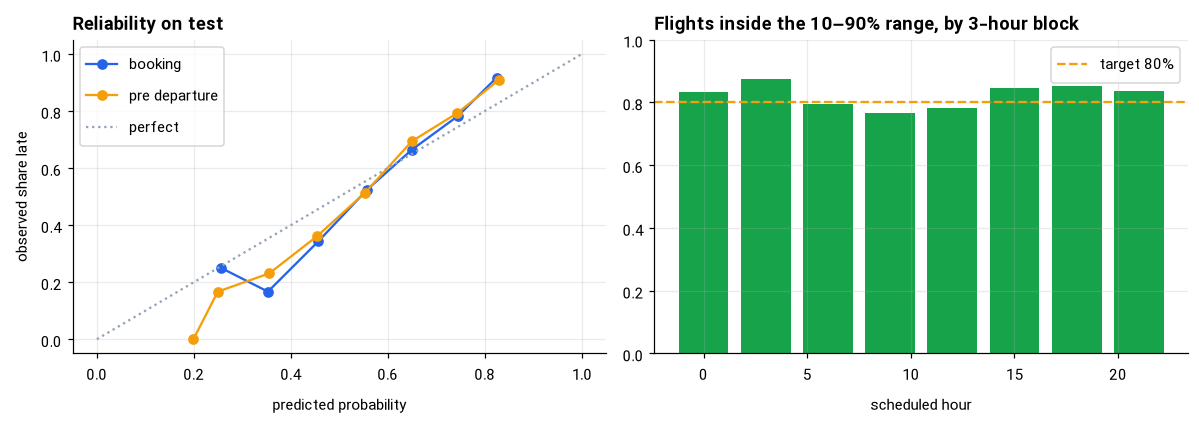

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for (variant, out), color in zip(outputs.items(), [BLUE, ORANGE]):
    bins = pd.cut(out["p_delay_over_15"], np.linspace(0, 1, 11))
    curve = pd.DataFrame({"p": out["p_delay_over_15"], "late": late}).groupby(bins, observed=True).agg(p=("p", "mean"), late=("late", "mean"), n=("late", "size"))
    left.plot(curve["p"], curve["late"], marker="o", color=color, label=variant.replace("_", " "))
left.plot([0, 1], [0, 1], color=GREY, ls=":", label="perfect")
left.set_xlabel("predicted probability")
left.set_ylabel("observed share late")
left.set_title("Reliability on test")
left.legend()
out = outputs["pre_departure"]
inside = (out["p10"] <= y) & (y <= out["p90"])
by_hour = pd.Series(inside.to_numpy()).groupby(test["Scheduled_Hour_of_Day"].to_numpy() // 3 * 3).mean()
right.bar(by_hour.index, by_hour.values, width=2.4, color=GREEN)
right.axhline(0.8, color=ORANGE, ls="--", label="target 80%")
right.set_ylim(0, 1)
right.set_title("Flights inside the 10–90% range, by 3-hour block")
right.set_xlabel("scheduled hour")
right.legend()
plt.tight_layout()

## Where the model is wrong

In [5]:
errors = test.assign(error=np.abs(y - outputs["pre_departure"]["p50"].to_numpy()), previous_known=test["prev_departure_delay_min"].notna())
segments = pd.concat({
    "previous delay known": errors.groupby("previous_known")["error"].agg(["mean", "size"]),
    "time of day": errors.groupby("scheduled_time_of_day")["error"].agg(["mean", "size"]),
}).rename(columns={"mean": "MAE", "size": "flights"})
segments.round(1)

MAE  flights
previous delay known False      24.9      463
                     True       19.1      224
time of day          Afternoon  22.6      145
                     Evening    21.7      208
                     Morning    24.2      200
                     Night      23.7      134

The model is clearly better when it knows the aircraft's previous delay; without it, it falls back to airline and time patterns. More registrations would help this model more than more rows.

## What the probability relies on (SHAP)

Text(0.5, 0, 'mean absolute contribution')

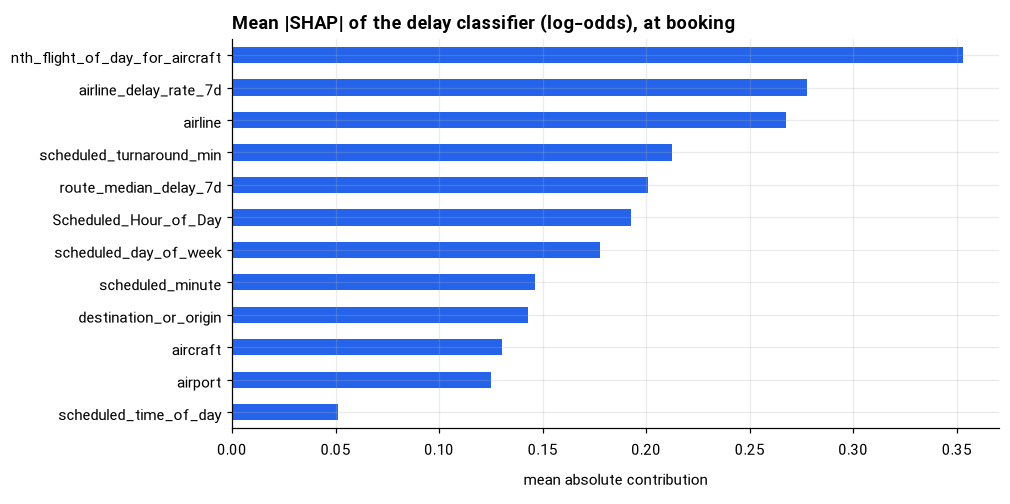

In [6]:
bundle = fits["booking"].bundle
X = prepare_input(test, bundle.features)
shap_values = bundle.shap_values(X)
importance = shap_values.abs().mean().sort_values().tail(12)
ax = importance.plot.barh(color=BLUE, figsize=(9, 4.6))
ax.set_title("Mean |SHAP| of the delay classifier (log-odds), at booking")
ax.set_xlabel("mean absolute contribution")

SHAP shows what the model uses, not what improves it: `nth_flight_of_day_for_aircraft` ranks high partly because it is missing for flights without a registration, so its missing-value indicator acts as an "is this Mehrabad?" flag. The ablation in the evaluation report is the measure of value.

## Why the split must be chronological

The first version of this project split flights at random. Flights on the same day share weather, congestion and knock-on delays, so a random split lets the model learn the test days from their neighbours:

In [7]:
from sklearn.model_selection import train_test_split

from aeroscrape.models.train import build_quantile_regressor
from aeroscrape.features.preprocess import variant_feature_set

features = variant_feature_set(config, "pre_departure")
everything = pd.concat([splits.train_val, splits.test])
lgbm = dict(config["pipeline"]["lgbm_params"])


def median_mae(train, holdout):
    model = build_quantile_regressor(config["pipeline"], lgbm, features, 0.5).fit(prepare_input(train, features), train["delay_minutes"])
    return np.mean(np.abs(holdout["delay_minutes"] - model.predict(prepare_input(holdout, features))))


random_train, random_test = train_test_split(everything, test_size=len(splits.test), random_state=0)
pd.Series({
    "random split (what version 1 did)": median_mae(random_train, random_test),
    "chronological split (the future)": median_mae(splits.train_val, splits.test),
}, name="MAE (min)").round(1)

random split (what version 1 did)    21.9
chronological split (the future)     23.0
Name: MAE (min), dtype: float64

## Takeaways

- The model beats the baselines with calibrated probabilities and a range that holds about 8 in 10 flights.
- It is best where it knows the aircraft's rotation; that is the data gap to close.
- Evaluation on future days is the only honest one: a random split gives a different, optimistic answer.